/opt/miniconda3/envs/geostats2026/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


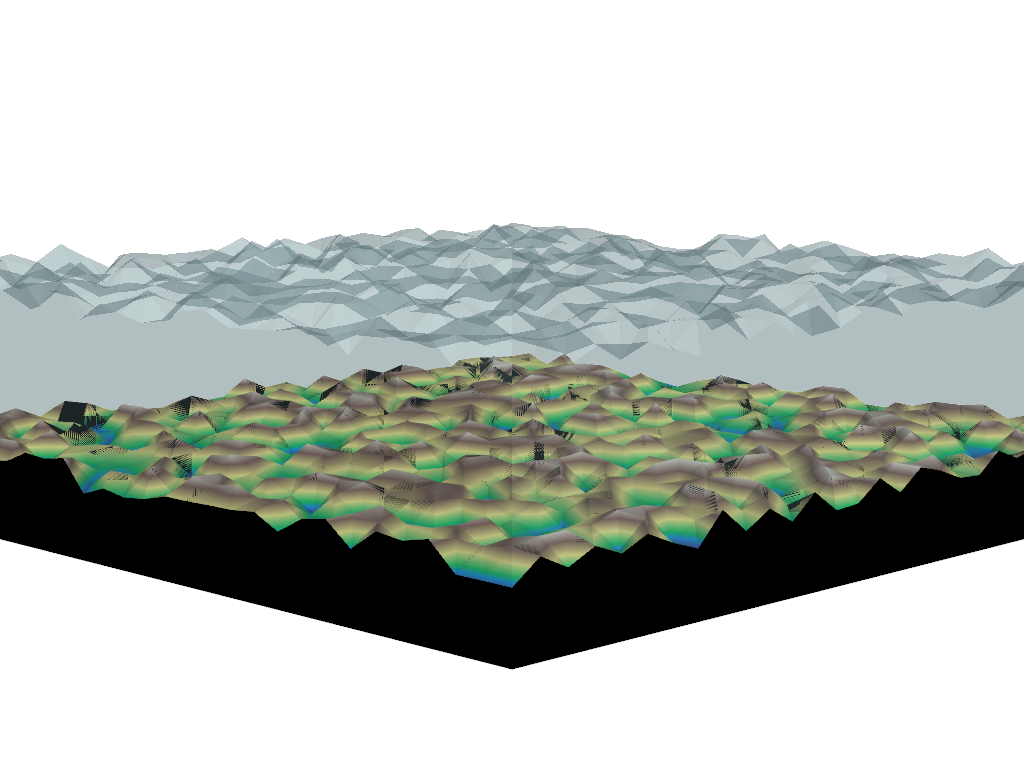

In [1]:
import pyvista as pv
import numpy as np

def plot_pyvista_block(surface_grid, bed_grid, resolution=500.0, z_exaggeration=5.0, zoom_level=1.7):
    h, w = surface_grid.shape
    
    # Convert pixel index to real-world meters
    x, y = np.meshgrid(np.arange(w, dtype=float) * resolution, 
                       np.arange(h, dtype=float) * resolution)
    
    # 1. Define the deep base elevation
    min_z = float(bed_grid.min() - 200)

    # 2. Build the solid Bedrock volume
    z_bed = np.stack([np.full((h, w), min_z), bed_grid], axis=-1).astype(float)
    x_grid = np.stack([x, x], axis=-1)
    y_grid = np.stack([y, y], axis=-1)
    bedrock_volume = pv.StructuredGrid(x_grid, y_grid, z_bed)

    # 3. Build the translucent Ice volume
    z_ice = np.stack([bed_grid, surface_grid], axis=-1).astype(float)
    ice_volume = pv.StructuredGrid(x_grid, y_grid, z_ice)

    # 4. Extract the top bedrock surface for the terrain colors
    bedrock_surface = pv.StructuredGrid(x, y, bed_grid.astype(float))
    bedrock_surface["Elevation"] = bed_grid.flatten(order="F") 

    # 5. Initialize the renderer
    plotter = pv.Plotter(notebook=True)
    
    plotter.add_mesh(bedrock_volume, color='black', show_edges=False)
    plotter.add_mesh(bedrock_surface, scalars="Elevation", cmap='terrain', 
                     show_edges=False, show_scalar_bar=False)
    plotter.add_mesh(ice_volume, color='lightblue', opacity=0.3, show_edges=False)

    # 6. Camera and Formatting 
    plotter.set_background('white')
    plotter.set_scale(zscale=z_exaggeration)
    plotter.view_isometric()
    
    # Zoom in significantly closer (increase this number to zoom tighter)
    plotter.camera.zoom(zoom_level)
    
    plotter.show(jupyter_backend='static')

# Generate standard 50x50 mock data
mock_bed = np.random.rand(50, 50) * 100
mock_surface = mock_bed + 500 + (np.random.rand(50, 50) * 50)

# Slice a smaller 30x30 section out of the middle of the arrays 
# (Use this exact slicing method on your real BedMachine data)
cropped_bed = mock_bed[10:40, 10:40]
cropped_surface = mock_surface[10:40, 10:40]

# Execute the plot on the smaller section with a higher zoom
plot_pyvista_block(cropped_surface, cropped_bed, resolution=500.0, z_exaggeration=5.0, zoom_level=1.7)

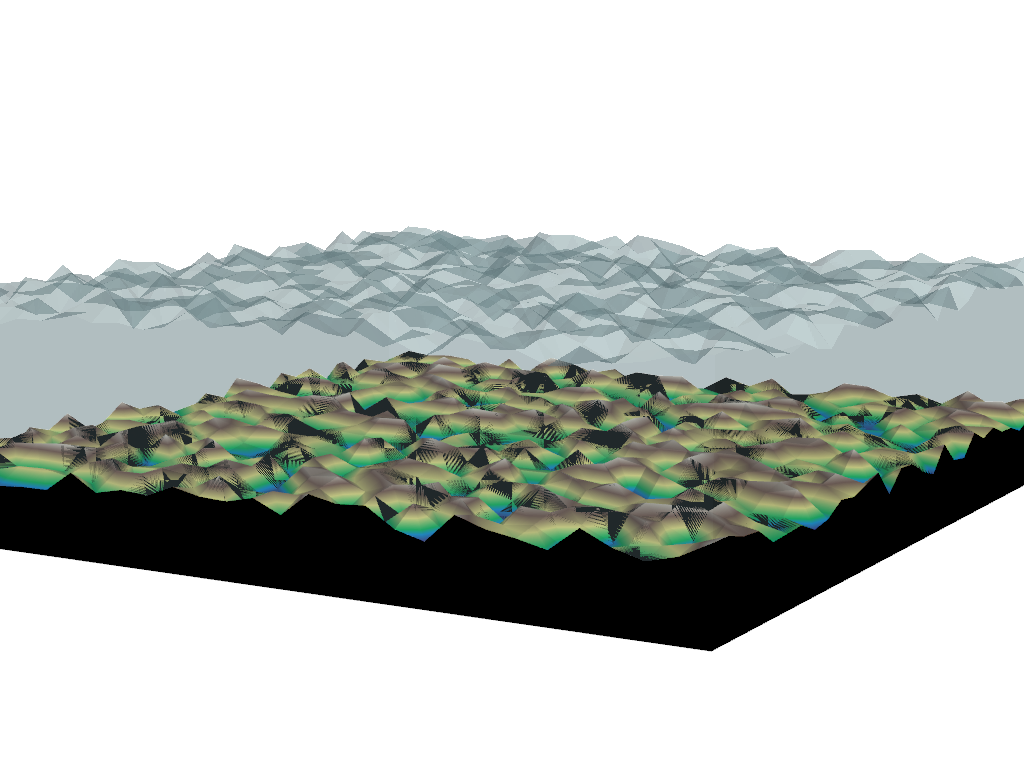

In [2]:
import pyvista as pv
import numpy as np

def plot_pyvista_block(surface_grid, bed_grid, resolution=500.0, z_exaggeration=5.0, zoom_level=1.7):
    h, w = surface_grid.shape
    
    # Convert pixel index to real-world meters
    x, y = np.meshgrid(np.arange(w, dtype=float) * resolution, 
                       np.arange(h, dtype=float) * resolution)
    
    # 1. Define the deep base elevation
    min_z = float(bed_grid.min() - 200)

    # 2. Build the solid Bedrock volume
    z_bed = np.stack([np.full((h, w), min_z), bed_grid], axis=-1).astype(float)
    x_grid = np.stack([x, x], axis=-1)
    y_grid = np.stack([y, y], axis=-1)
    bedrock_volume = pv.StructuredGrid(x_grid, y_grid, z_bed)

    # 3. Build the translucent Ice volume
    z_ice = np.stack([bed_grid, surface_grid], axis=-1).astype(float)
    ice_volume = pv.StructuredGrid(x_grid, y_grid, z_ice)

    # 4. Extract the top bedrock surface for the terrain colors
    bedrock_surface = pv.StructuredGrid(x, y, bed_grid.astype(float))
    bedrock_surface["Elevation"] = bed_grid.flatten(order="F") 

    # 5. Initialize the renderer
    plotter = pv.Plotter(notebook=True)
    
    plotter.add_mesh(bedrock_volume, color='black', show_edges=False)
    plotter.add_mesh(bedrock_surface, scalars="Elevation", cmap='terrain', 
                     show_edges=False, show_scalar_bar=False)
    plotter.add_mesh(ice_volume, color='lightblue', opacity=0.3, show_edges=False)

    # 6. Camera and Formatting 
    plotter.set_background('white')
    plotter.set_scale(zscale=z_exaggeration)
    
    # Set camera to face the side, then rotate 30 degrees
    plotter.camera_position = 'yz' 
    plotter.camera.azimuth = 30
    plotter.camera.elevation = 8.5  # Slight tilt down to see the surface
    
    # Zoom in significantly closer (increase this number to zoom tighter)
    plotter.camera.zoom(zoom_level)
    
    plotter.show(jupyter_backend='static')

# Generate standard 50x50 mock data
mock_bed = np.random.rand(50, 50) * 100
mock_surface = mock_bed + 500 + (np.random.rand(50, 50) * 50)

# Slice a smaller 30x30 section out of the middle of the arrays 
# (Use this exact slicing method on your real BedMachine data)
cropped_bed = mock_bed[10:40, 10:40]
cropped_surface = mock_surface[10:40, 10:40]

# Execute the plot on the smaller section with a higher zoom
plot_pyvista_block(cropped_surface, cropped_bed, resolution=500.0, z_exaggeration=5.0, zoom_level=1.6)

/opt/miniconda3/envs/geostats2026/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/var/folders/69/_jjck6ps7y79pm228mllrfdm0000gn/T/ipykernel_21284/434921629.py:45: PyVistaDeprecationWarning: `xlabel` is deprecated. Use `xtitle` instead.
  plotter.show_bounds(
/var/folders/69/_jjck6ps7y79pm228mllrfdm0000gn/T/ipykernel_21284/434921629.py:45: PyVistaDeprecationWarning: `ylabel` is deprecated. Use `ytitle` instead.
  plotter.show_bounds(
/var/folders/69/_jjck6ps7y79pm228mllrfdm0000gn/T/ipykernel_21284/434921629.py:45: PyVistaDeprecationWarning: `zlabel` is deprecated. Use `ztitle` instead.
  plotter.show_bounds(


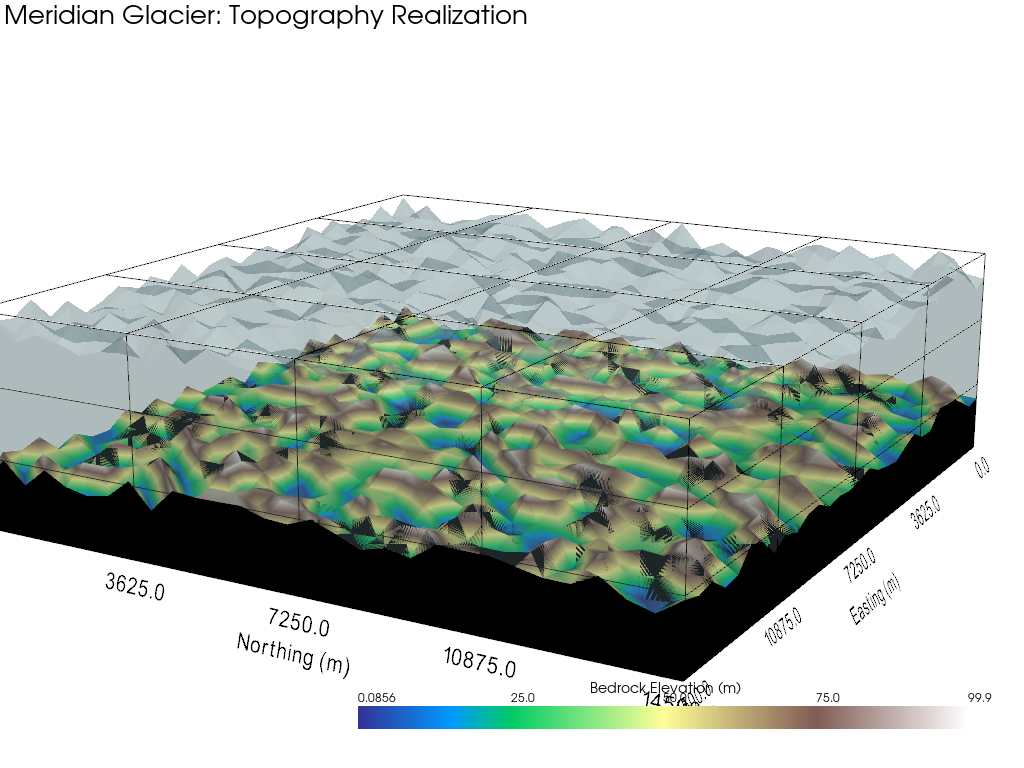

In [1]:
import pyvista as pv
import numpy as np

def plot_pyvista_block(surface_grid, bed_grid, resolution=500.0, z_exaggeration=5.0, zoom_level=1.4):
    h, w = surface_grid.shape
    
    # Convert pixel index to real-world meters
    x, y = np.meshgrid(np.arange(w, dtype=float) * resolution, 
                       np.arange(h, dtype=float) * resolution)
    
    # 1. Define the deep base elevation
    min_z = float(bed_grid.min() - 200)

    # 2. Build the solid Bedrock volume
    z_bed = np.stack([np.full((h, w), min_z), bed_grid], axis=-1).astype(float)
    x_grid = np.stack([x, x], axis=-1)
    y_grid = np.stack([y, y], axis=-1)
    bedrock_volume = pv.StructuredGrid(x_grid, y_grid, z_bed)

    # 3. Build the translucent Ice volume
    z_ice = np.stack([bed_grid, surface_grid], axis=-1).astype(float)
    ice_volume = pv.StructuredGrid(x_grid, y_grid, z_ice)

    # 4. Extract the top bedrock surface for the terrain colors
    bedrock_surface = pv.StructuredGrid(x, y, bed_grid.astype(float))
    bedrock_surface["Elevation (m)"] = bed_grid.flatten(order="F") 

    # 5. Initialize the renderer
    plotter = pv.Plotter(notebook=True)
    
    plotter.add_mesh(bedrock_volume, color='black', show_edges=False)
    
    # Add Colorbar (Rubric Requirement)
    sbar_args = dict(title="Bedrock Elevation (m)", title_font_size=14, label_font_size=12, color="black")
    plotter.add_mesh(bedrock_surface, scalars="Elevation (m)", cmap='terrain', 
                     show_edges=False, scalar_bar_args=sbar_args)
                     
    plotter.add_mesh(ice_volume, color='lightblue', opacity=0.3, show_edges=False)

    # 6. Camera and Formatting 
    plotter.set_background('white')
    plotter.set_scale(zscale=z_exaggeration)
    
    # Add axes grid with physical units (Easting/Northing are standard for polar stereographic)
    plotter.show_bounds(
        grid='front',
        location='outer',
        all_edges=False,
        xlabel='Easting (m)',
        ylabel='Northing (m)',
        zlabel='Elevation (m)',
        color='black'
    )
    
    # Add Figure Title
    plotter.add_text("Meridian Glacier: Topography Realization", position='upper_left', color='black', font_size=14)

    # Camera settings
    plotter.camera_position = 'yz' 
    plotter.camera.azimuth = 30
    plotter.camera.elevation = 15  
    plotter.camera.zoom(zoom_level)
    
    plotter.show(jupyter_backend='static')

# Generate standard 50x50 mock data
mock_bed = np.random.rand(50, 50) * 100
mock_surface = mock_bed + 500 + (np.random.rand(50, 50) * 50)

# Slice a smaller 30x30 section 
cropped_bed = mock_bed[10:40, 10:40]
cropped_surface = mock_surface[10:40, 10:40]

# Execute the plot
plot_pyvista_block(cropped_surface, cropped_bed, resolution=500.0, z_exaggeration=5.0, zoom_level=1.4)

/var/folders/69/_jjck6ps7y79pm228mllrfdm0000gn/T/ipykernel_21284/1443961558.py:55: PyVistaDeprecationWarning: `xlabel` is deprecated. Use `xtitle` instead.
  plotter.show_bounds(
/var/folders/69/_jjck6ps7y79pm228mllrfdm0000gn/T/ipykernel_21284/1443961558.py:55: PyVistaDeprecationWarning: `ylabel` is deprecated. Use `ytitle` instead.
  plotter.show_bounds(
/var/folders/69/_jjck6ps7y79pm228mllrfdm0000gn/T/ipykernel_21284/1443961558.py:55: PyVistaDeprecationWarning: `zlabel` is deprecated. Use `ztitle` instead.
  plotter.show_bounds(


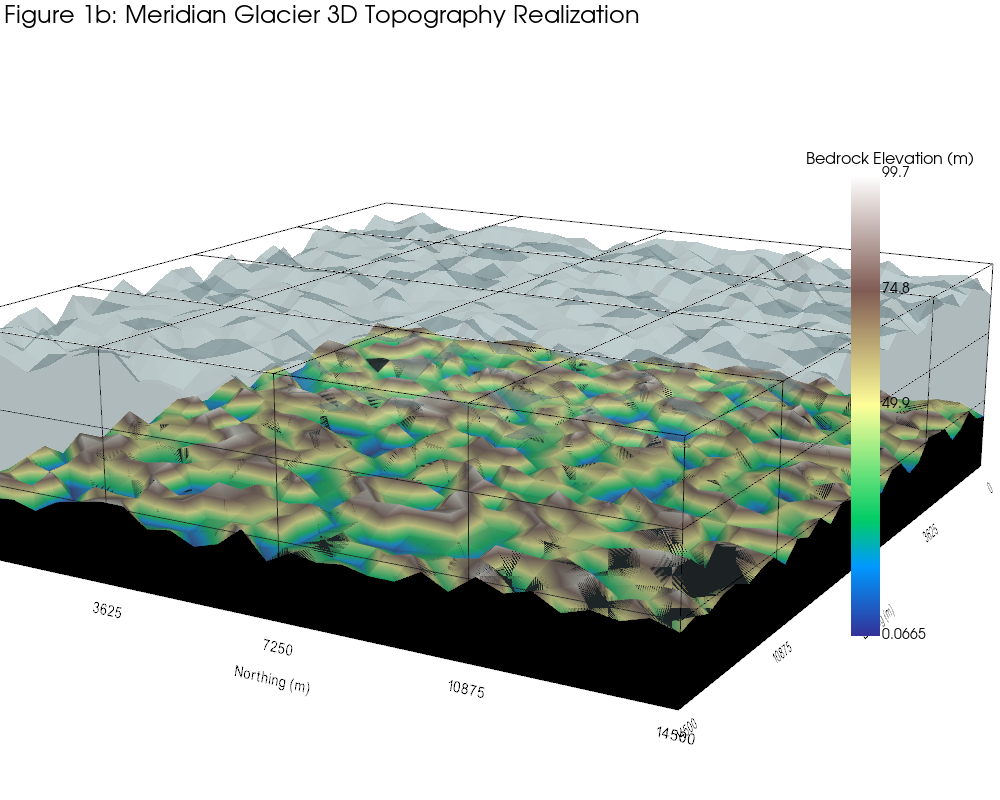

In [3]:
import pyvista as pv
import numpy as np

def plot_pyvista_block(surface_grid, bed_grid, resolution=500.0, z_exaggeration=5.0, zoom_level=1.4):
    h, w = surface_grid.shape
    
    # Convert pixel index to real-world meters
    x, y = np.meshgrid(np.arange(w, dtype=float) * resolution, 
                       np.arange(h, dtype=float) * resolution)
    
    # 1. Define the deep base elevation
    min_z = float(bed_grid.min() - 200)

    # 2. Build the solid Bedrock volume
    z_bed = np.stack([np.full((h, w), min_z), bed_grid], axis=-1).astype(float)
    x_grid = np.stack([x, x], axis=-1)
    y_grid = np.stack([y, y], axis=-1)
    bedrock_volume = pv.StructuredGrid(x_grid, y_grid, z_bed)

    # 3. Build the translucent Ice volume
    z_ice = np.stack([bed_grid, surface_grid], axis=-1).astype(float)
    ice_volume = pv.StructuredGrid(x_grid, y_grid, z_ice)

    # 4. Extract the top bedrock surface for the terrain colors
    bedrock_surface = pv.StructuredGrid(x, y, bed_grid.astype(float))
    bedrock_surface["Elevation (m)"] = bed_grid.flatten(order="F") 

    # 5. Initialize the renderer with a LARGER window size to fix "smooshed" text
    plotter = pv.Plotter(notebook=True, window_size=[1000, 800])
    
    plotter.add_mesh(bedrock_volume, color='black', show_edges=False)
    
    # Move colorbar to the right side and increase font size
    sbar_args = dict(
        title="Bedrock Elevation (m)", 
        title_font_size=16, 
        label_font_size=14, 
        color="black",
        position_x=0.85, 
        position_y=0.2, 
        height=0.6, 
        vertical=True
    )
    plotter.add_mesh(bedrock_surface, scalars="Elevation (m)", cmap='terrain', 
                     show_edges=False, scalar_bar_args=sbar_args)
                     
    # Intuitive ice color: translucent blue/white
    plotter.add_mesh(ice_volume, color='lightblue', opacity=0.3, show_edges=False)

    # 6. Camera and Formatting 
    plotter.set_background('white')
    plotter.set_scale(zscale=z_exaggeration)
    
    # Add axes grid with formatting to prevent number overlapping
    plotter.show_bounds(
        grid='front',
        location='outer',
        all_edges=False,
        xlabel='Easting (m)',
        ylabel='Northing (m)',
        zlabel='Elevation (m)',
        color='black',
        fmt="%.0f",       # Removes messy decimals from the axis numbers
        font_size=12      # Ensures the axis labels are readable
    )
    
    # Add Figure Title
    plotter.add_text("Figure 1b: Meridian Glacier 3D Topography Realization", 
                     position='upper_left', color='black', font_size=14)

    # Set camera to face the side, then rotate 30 degrees
    plotter.camera_position = 'yz' 
    plotter.camera.azimuth = 30
    plotter.camera.elevation = 15  
    plotter.camera.zoom(zoom_level)
    
    plotter.show(jupyter_backend='static')

# Generate standard 50x50 mock data
mock_bed = np.random.rand(50, 50) * 100
mock_surface = mock_bed + 500 + (np.random.rand(50, 50) * 50)

# Slice a smaller 30x30 section 
cropped_bed = mock_bed[10:40, 10:40]
cropped_surface = mock_surface[10:40, 10:40]

# Execute the plot
plot_pyvista_block(cropped_surface, cropped_bed, resolution=500.0, z_exaggeration=5.0, zoom_level=1.4)

/var/folders/69/_jjck6ps7y79pm228mllrfdm0000gn/T/ipykernel_21284/603342454.py:56: PyVistaDeprecationWarning: `xlabel` is deprecated. Use `xtitle` instead.
  plotter.show_bounds(
/var/folders/69/_jjck6ps7y79pm228mllrfdm0000gn/T/ipykernel_21284/603342454.py:56: PyVistaDeprecationWarning: `ylabel` is deprecated. Use `ytitle` instead.
  plotter.show_bounds(
/var/folders/69/_jjck6ps7y79pm228mllrfdm0000gn/T/ipykernel_21284/603342454.py:56: PyVistaDeprecationWarning: `zlabel` is deprecated. Use `ztitle` instead.
  plotter.show_bounds(


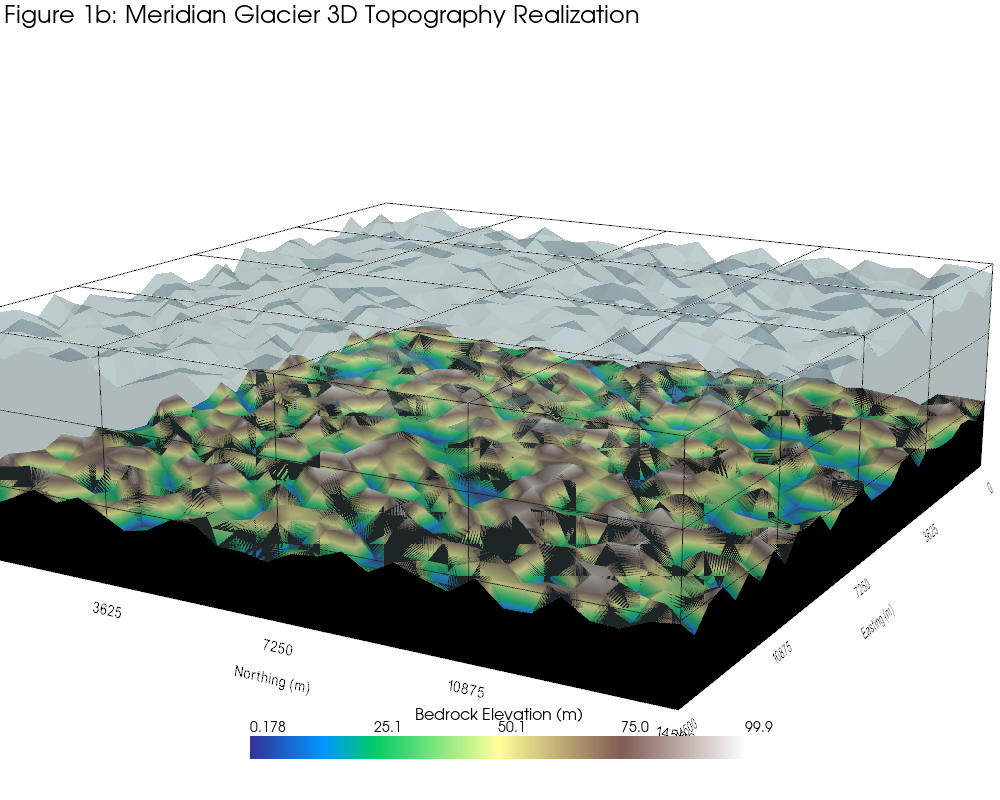

In [5]:
import pyvista as pv
import numpy as np

def plot_pyvista_block(surface_grid, bed_grid, resolution=500.0, z_exaggeration=5.0, zoom_level=1.4):
    h, w = surface_grid.shape
    
    # Convert pixel index to real-world meters
    x, y = np.meshgrid(np.arange(w, dtype=float) * resolution, 
                       np.arange(h, dtype=float) * resolution)
    
    # 1. Define the deep base elevation
    min_z = float(bed_grid.min() - 200)

    # 2. Build the solid Bedrock volume
    z_bed = np.stack([np.full((h, w), min_z), bed_grid], axis=-1).astype(float)
    x_grid = np.stack([x, x], axis=-1)
    y_grid = np.stack([y, y], axis=-1)
    bedrock_volume = pv.StructuredGrid(x_grid, y_grid, z_bed)

    # 3. Build the translucent Ice volume
    z_ice = np.stack([bed_grid, surface_grid], axis=-1).astype(float)
    ice_volume = pv.StructuredGrid(x_grid, y_grid, z_ice)

    # 4. Extract the top bedrock surface for the terrain colors
    bedrock_surface = pv.StructuredGrid(x, y, bed_grid.astype(float))
    bedrock_surface["Elevation (m)"] = bed_grid.flatten(order="F") 

    # 5. Initialize the renderer with a LARGER window size
    plotter = pv.Plotter(notebook=True, window_size=[1000, 800])
    
    plotter.add_mesh(bedrock_volume, color='black', show_edges=False)
    
    # MOVED COLORBAR: Positioned horizontally at the bottom to prevent overlapping
    sbar_args = dict(
        title="Bedrock Elevation (m)", 
        title_font_size=16, 
        label_font_size=14, 
        color="black",
        position_x=0.25,  # Centers the bar horizontally
        position_y=0.05,  # Pushes the bar to the bottom edge
        width=0.5,        # Makes the bar span half the window width
        height=0.08,      # Sets a thin profile for the horizontal bar
        vertical=False    # Changes orientation from vertical to horizontal
    )
    plotter.add_mesh(bedrock_surface, scalars="Elevation (m)", cmap='terrain', 
                     show_edges=False, scalar_bar_args=sbar_args)
                     
    # Intuitive ice color: translucent blue/white
    plotter.add_mesh(ice_volume, color='lightblue', opacity=0.3, show_edges=False)

    # 6. Camera and Formatting 
    plotter.set_background('white')
    plotter.set_scale(zscale=z_exaggeration)
    
    # Add axes grid with formatting to prevent number overlapping
    plotter.show_bounds(
        grid='front',
        location='outer',
        all_edges=False,
        xlabel='Easting (m)',
        ylabel='Northing (m)',
        zlabel='Elevation (m)',
        color='black',
        fmt="%.0f",       
        font_size=12      
    )
    
    # Add Figure Title
    plotter.add_text("Figure 1b: Meridian Glacier 3D Topography Realization", 
                     position='upper_left', color='black', font_size=14)

    # Set camera to face the side, then rotate 30 degrees
    plotter.camera_position = 'yz' 
    plotter.camera.azimuth = 30
    plotter.camera.elevation = 15  
    plotter.camera.zoom(zoom_level)
    
    plotter.show(jupyter_backend='static')

# Generate standard 50x50 mock data
mock_bed = np.random.rand(50, 50) * 100
mock_surface = mock_bed + 500 + (np.random.rand(50, 50) * 50)

# Slice a smaller 30x30 section 
cropped_bed = mock_bed[10:40, 10:40]
cropped_surface = mock_surface[10:40, 10:40]

# Execute the plot
plot_pyvista_block(cropped_surface, cropped_bed, resolution=500.0, z_exaggeration=5.0, zoom_level=1.4)

/opt/miniconda3/envs/geostats2026/lib/python3.12/site-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_physical/ne_50m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/opt/miniconda3/envs/geostats2026/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/miniconda3/envs/geostats2026/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


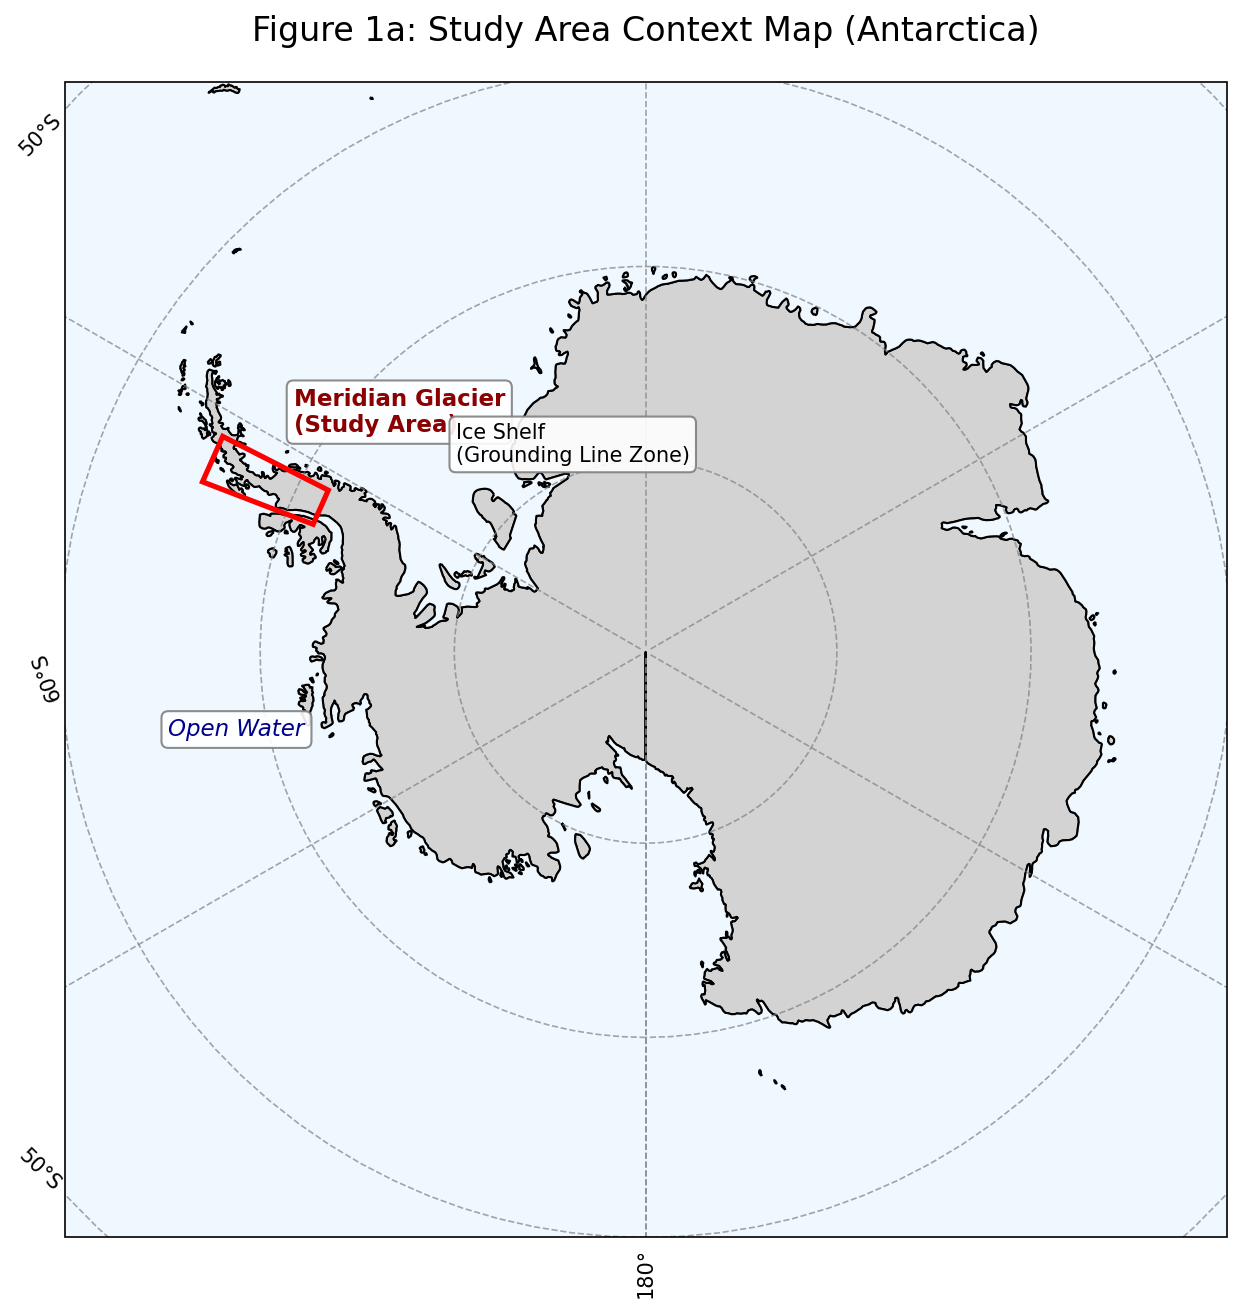

In [4]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.patches as mpatches

# Create a large, high-resolution figure
fig = plt.figure(figsize=(10, 10), dpi=150)
ax = plt.axes(projection=ccrs.SouthPolarStereo())

# Limit the map to Antarctica's extent
ax.set_extent([-180, 180, -90, -60], ccrs.PlateCarree())

# Add Continent Outline and Oceans (Rubric Requirement)
ax.add_feature(cfeature.LAND, facecolor='lightgrey', edgecolor='black', linewidth=1)
ax.add_feature(cfeature.OCEAN, facecolor='aliceblue')
ax.coastlines(resolution='50m', color='black', linewidth=1)

# Add Latitude and Longitude Gridlines (Rubric Requirement)
gl = ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False, 
                  color='gray', linestyle='--', alpha=0.7)
gl.top_labels = False
gl.right_labels = False

# Approximate coordinates for Meridian Glacier / Antarctic Peninsula study area
study_lon, study_lat = -66.0, -68.5 

# Outline around your study area (Rubric Requirement)
study_area_box = mpatches.Rectangle(
    xy=(study_lon - 3, study_lat - 3), width=6, height=6,
    edgecolor='red', facecolor='none', linewidth=2.5,
    transform=ccrs.PlateCarree(), zorder=10
)
ax.add_patch(study_area_box)

# Labeled Glaciers, Place Names, Grounding Line, and Open Water (Rubric Requirement)
# We use bbox (bounding boxes) to ensure the text is highly legible against the map background
text_props = dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='gray', alpha=0.9)

ax.text(study_lon + 8, study_lat, 'Meridian Glacier\n(Study Area)', 
        transform=ccrs.PlateCarree(), fontsize=11, fontweight='bold', color='darkred', bbox=text_props)

ax.text(-45, -76, 'Ice Shelf \n(Grounding Line Zone)', 
        transform=ccrs.PlateCarree(), fontsize=10, color='black', bbox=text_props)

ax.text(-100, -65, 'Open Water', 
        transform=ccrs.PlateCarree(), fontsize=11, color='darkblue', fontstyle='italic', bbox=text_props)

plt.title("Figure 1a: Study Area Context Map (Antarctica)", fontsize=16, pad=20)
plt.show()

/var/folders/69/_jjck6ps7y79pm228mllrfdm0000gn/T/ipykernel_21284/2707968175.py:55: PyVistaDeprecationWarning: `xlabel` is deprecated. Use `xtitle` instead.
  plotter.show_bounds(
/var/folders/69/_jjck6ps7y79pm228mllrfdm0000gn/T/ipykernel_21284/2707968175.py:55: PyVistaDeprecationWarning: `ylabel` is deprecated. Use `ytitle` instead.
  plotter.show_bounds(
/var/folders/69/_jjck6ps7y79pm228mllrfdm0000gn/T/ipykernel_21284/2707968175.py:55: PyVistaDeprecationWarning: `zlabel` is deprecated. Use `ztitle` instead.
  plotter.show_bounds(


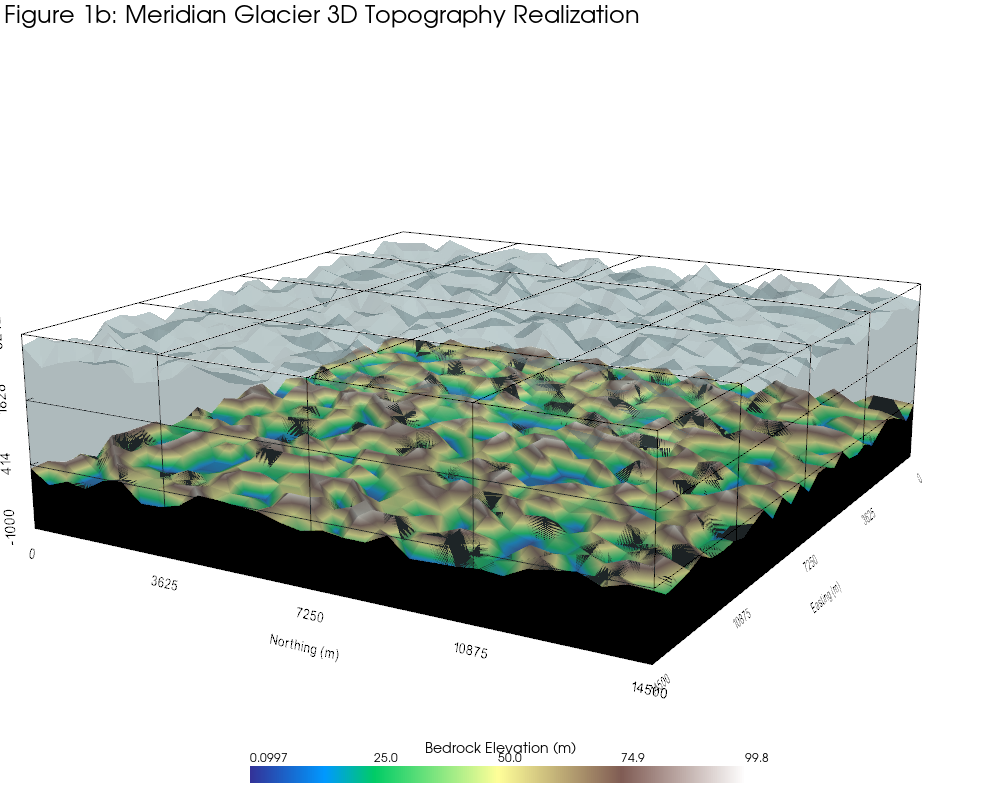

In [6]:
import pyvista as pv
import numpy as np

def plot_pyvista_block(surface_grid, bed_grid, resolution=500.0, z_exaggeration=5.0, zoom_level=1.2):
    h, w = surface_grid.shape
    
    # Convert pixel index to real-world meters
    x, y = np.meshgrid(np.arange(w, dtype=float) * resolution, 
                       np.arange(h, dtype=float) * resolution)
    
    # 1. Define the deep base elevation
    min_z = float(bed_grid.min() - 200)

    # 2. Build the solid Bedrock volume
    z_bed = np.stack([np.full((h, w), min_z), bed_grid], axis=-1).astype(float)
    x_grid = np.stack([x, x], axis=-1)
    y_grid = np.stack([y, y], axis=-1)
    bedrock_volume = pv.StructuredGrid(x_grid, y_grid, z_bed)

    # 3. Build the translucent Ice volume
    z_ice = np.stack([bed_grid, surface_grid], axis=-1).astype(float)
    ice_volume = pv.StructuredGrid(x_grid, y_grid, z_ice)

    # 4. Extract the top bedrock surface for the terrain colors
    bedrock_surface = pv.StructuredGrid(x, y, bed_grid.astype(float))
    bedrock_surface["Elevation (m)"] = bed_grid.flatten(order="F") 

    # 5. Initialize the renderer with a large window size
    plotter = pv.Plotter(notebook=True, window_size=[1000, 800])
    
    plotter.add_mesh(bedrock_volume, color='black', show_edges=False)
    
    # ADJUSTED COLORBAR: Placed at the very bottom edge in the newly created whitespace
    sbar_args = dict(
        title="Bedrock Elevation (m)", 
        title_font_size=14, 
        label_font_size=12, 
        color="black",
        position_x=0.25,  
        position_y=0.02,  # Pushed to the absolute bottom margin
        width=0.5,        
        height=0.06,      # Slightly thinner profile
        vertical=False    
    )
    plotter.add_mesh(bedrock_surface, scalars="Elevation (m)", cmap='terrain', 
                     show_edges=False, scalar_bar_args=sbar_args)
                     
    plotter.add_mesh(ice_volume, color='lightblue', opacity=0.3, show_edges=False)

    # 6. Camera and Formatting 
    plotter.set_background('white')
    plotter.set_scale(zscale=z_exaggeration)
    
    # Add axes grid
    plotter.show_bounds(
        grid='front',
        location='outer',
        all_edges=False,
        xlabel='Easting (m)',
        ylabel='Northing (m)',
        zlabel='Elevation (m)',
        color='black',
        fmt="%.0f",       
        font_size=11      # Dropped by 1pt to ensure it doesn't crowd
    )
    
    # Add Figure Title
    plotter.add_text("Figure 1b: Meridian Glacier 3D Topography Realization", 
                     position='upper_left', color='black', font_size=14)

    # Camera angles
    plotter.camera_position = 'yz' 
    plotter.camera.azimuth = 30
    plotter.camera.elevation = 15  
    
    # ZOOM REDUCED: Pulls the axis numbers up and away from the legend at the bottom
    plotter.camera.zoom(zoom_level) 
    
    plotter.show(jupyter_backend='static')

# Generate standard 50x50 mock data
mock_bed = np.random.rand(50, 50) * 100
mock_surface = mock_bed + 500 + (np.random.rand(50, 50) * 50)

# Slice a smaller 30x30 section 
cropped_bed = mock_bed[10:40, 10:40]
cropped_surface = mock_surface[10:40, 10:40]

# Execute the plot (using zoom_level=1.2 now)
plot_pyvista_block(cropped_surface, cropped_bed, resolution=500.0, z_exaggeration=5.0, zoom_level=1.2)

/opt/miniconda3/envs/geostats2026/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/miniconda3/envs/geostats2026/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


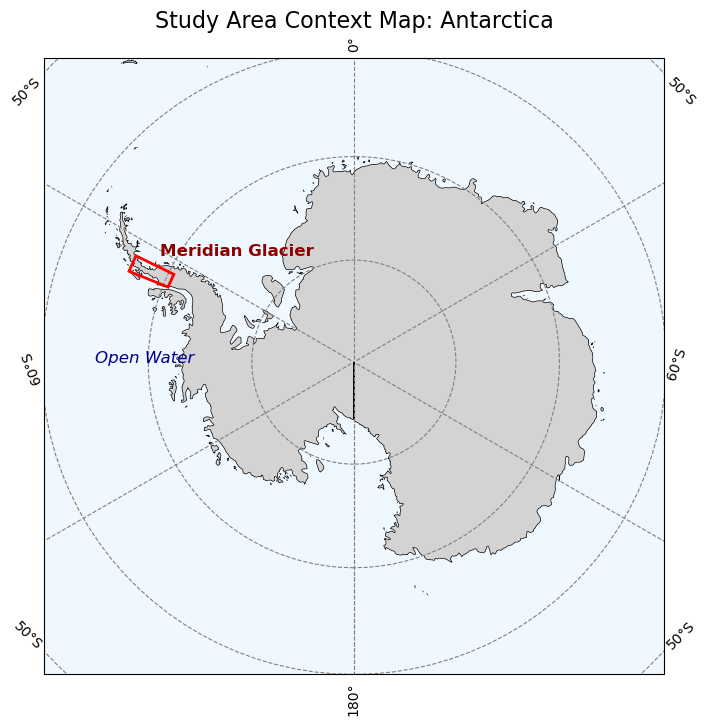

In [7]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.patches as mpatches

fig = plt.figure(figsize=(8, 8))
# South Polar Stereographic is the standard projection for Antarctica
ax = plt.axes(projection=ccrs.SouthPolarStereo())

# Set map extent to show Antarctica
ax.set_extent([-180, 180, -90, -60], ccrs.PlateCarree())

# Add geographic features
ax.add_feature(cfeature.LAND, facecolor='lightgrey', edgecolor='black')
ax.add_feature(cfeature.OCEAN, facecolor='aliceblue')

# Add Latitude and Longitude Gridlines (Rubric Requirement)
ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False, color='gray', linestyle='--')

# Define your study area coordinates (approximate for Meridian Glacier / Antarctic Peninsula)
study_lon, study_lat = -66.0, -68.5 

# Draw a red box around the study area
study_area_box = mpatches.Rectangle(
    xy=(study_lon - 2, study_lat - 2), width=4, height=4,
    edgecolor='red', facecolor='none', linewidth=2,
    transform=ccrs.PlateCarree(), zorder=10
)
ax.add_patch(study_area_box)

# Add prominent place names and features (Rubric Requirement)
ax.text(study_lon + 5, study_lat, 'Meridian Glacier', transform=ccrs.PlateCarree(), 
        fontsize=12, fontweight='bold', color='darkred')

# The Ice Shelf/Grounding Line text has been removed to keep the map visually clear.

ax.text(-90, -65, 'Open Water', transform=ccrs.PlateCarree(), 
        fontsize=12, color='darkblue', fontstyle='italic')

plt.title("Study Area Context Map: Antarctica", fontsize=16)
plt.show()